# # Cell 1: Install Dependencies

In [1]:
!pip install -q pytorch-grad-cam captum timm gdown opencv-python tqdm pandas matplotlib seaborn
print("Dependencies installed.")

ERROR: Could not find a version that satisfies the requirement pytorch-grad-cam (from versions: none)
ERROR: No matching distribution found for pytorch-grad-cam
Dependencies installed.


In [2]:
!pip install grad-cam captum timm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 921.5 kB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 6.1 MB/s eta 0:00:00
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=3ca1aaf57a587c6783885c00a801920b5c856f71950d1bc6ff35247da181671f
  Stored in directory: /root/.cache/pip/wheels/05/bd/e2/0c0eecf3c26b6cdb231b5656d53905bddc8090d69619d57e6b
Successfully built grad-cam


# # Cell 2: Imports and Configuration

In [3]:
import os
import sys
import gc
import json
import random
import warnings
import numpy as np
import pandas as pd
import cv2
from PIL import Image
from collections import defaultdict
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision.transforms as T
import timm

from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from captum.attr import IntegratedGradients

warnings.filterwarnings('ignore')

# ==================== CONFIGURATION ====================
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

FFPLUS_ROOT = "/kaggle/input/datasets/adham7elmy/faceforencispp-extracted-frames"
CELEB_DF_ROOT = "/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Test"

WORK_DIR = "/kaggle/working/trustvis_results"
os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(f"{WORK_DIR}/figures", exist_ok=True)
os.makedirs(f"{WORK_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{WORK_DIR}/attributions", exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 24  # Reduced slightly for larger models
TRAIN_EPOCHS = 6
LEARNING_RATE = 1e-4
NUM_WORKERS = 2
RANDOM_SEED = 42

N_TRAIN = 4000
N_TEST_FF = 2000
N_TEST_CROSS = 1000
N_IG_STEPS = 50

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_SEED)

Using device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


# # Cell 3: Download Face Parsing Pretrained Weights

In [4]:
import gdown

FACE_PARSING_WEIGHTS_PATH = f"{WORK_DIR}/79999_iter.pth"
FACE_PARSING_REPO_PATH = f"{WORK_DIR}/face-parsing.PyTorch"

if not os.path.exists(FACE_PARSING_REPO_PATH):
    !git clone https://github.com/zllrunning/face-parsing.PyTorch.git {FACE_PARSING_REPO_PATH}
    print("Cloned face-parsing repository.")
else:
    print("Face-parsing repository already exists.")

if not os.path.exists(FACE_PARSING_WEIGHTS_PATH):
    file_id = "154JgKpzCPW82qINcVieuPH3fZ2e0P812"
    gdown.download(id=file_id, output=FACE_PARSING_WEIGHTS_PATH, quiet=False)
    print(f"Downloaded face parsing weights.")
else:
    print(f"Face parsing weights already exist.")

Cloning into '/kaggle/working/trustvis_results/face-parsing.PyTorch'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 92 (delta 22), reused 17 (delta 17), pack-reused 52 (from 1)
Receiving objects: 100% (92/92), 3.06 MiB | 11.12 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Cloned face-parsing repository.


Downloading...
From: https://drive.google.com/uc?id=154JgKpzCPW82qINcVieuPH3fZ2e0P812
To: /kaggle/working/trustvis_results/79999_iter.pth
100%|██████████| 53.3M/53.3M [00:00<00:00, 162MB/s]

Downloaded face parsing weights.


# # Cell 4: Face Parsing Model (BiSeNet)

In [5]:
sys.path.insert(0, FACE_PARSING_REPO_PATH)

try:
    from model import BiSeNet
    print("Successfully imported BiSeNet from cloned repo.")
except Exception as e:
    print(f"Import error: {e}")
    print("Using inline BiSeNet fallback...")
    class BiSeNet(nn.Module):
        def __init__(self, n_classes=19):
            super(BiSeNet, self).__init__()
            self.n_classes = n_classes
            self.conv = nn.Sequential(
                nn.Conv2d(3, 64, 3, padding=1),
                nn.BatchNorm2d(64), nn.ReLU(inplace=True),
                nn.Conv2d(64, n_classes, 3, padding=1)
            )
        def forward(self, x):
            h, w = x.size()[2:]
            out = self.conv(x)
            out = F.interpolate(out, size=(h, w), mode='bilinear', align_corners=True)
            return (out, out, out)

N_PARSING_CLASSES = 19
face_parser = BiSeNet(n_classes=N_PARSING_CLASSES)
face_parser.load_state_dict(torch.load(FACE_PARSING_WEIGHTS_PATH, map_location='cpu'))
face_parser = face_parser.to(DEVICE)
face_parser.eval()

face_parse_transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

print("Face parsing model loaded.")

Successfully imported BiSeNet from cloned repo.
Downloading: "https://download.pytorch.org/models/resnet18-5c106cde.pth" to /root/.cache/torch/hub/checkpoints/resnet18-5c106cde.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 250MB/s]


Face parsing model loaded.


# # Cell 5: Face Parsing Helper Functions

In [6]:
REGION_MAP = {
    'eyes': [2, 3, 4, 5, 6],
    'nose': [10],
    'mouth': [11, 12, 13],
    'skin': [1],
    'hair': [17],
    'background': [0, 7, 8, 9, 14, 15, 16, 18]
}
REGION_NAMES = ['eyes', 'nose', 'mouth', 'skin', 'hair', 'background']

def parse_face(image_pil):
    orig_w, orig_h = image_pil.size
    image_512 = image_pil.resize((512, 512), Image.BILINEAR)
    tensor = face_parse_transform(image_512).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = face_parser(tensor)[0]
        parsing = out.squeeze(0).cpu().numpy().argmax(0)
    parsing = cv2.resize(parsing.astype(np.uint8), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    return parsing

def get_region_masks(parsing_mask):
    masks = {}
    for region_name, class_ids in REGION_MAP.items():
        mask = np.isin(parsing_mask, class_ids).astype(np.float32)
        masks[region_name] = mask
    return masks

def compute_region_attribution(saliency_map, region_masks):
    saliency = saliency_map.astype(np.float32)
    if saliency.sum() > 0:
        saliency = saliency / saliency.sum()
    attributions = {}
    for region_name, mask in region_masks.items():
        attribution = (saliency * mask).sum()
        attributions[region_name] = float(attribution * 100)
    return attributions

print("Face parsing helpers defined.")

Face parsing helpers defined.


# # Cell 6: Dataset Loader for FaceForensics++

In [7]:
# class DeepfakeDataset(Dataset):
#     def __init__(self, root_dir, transform=None, max_samples=None):
#         self.root_dir = root_dir
#         self.transform = transform
#         self.samples = []

#         real_dir = None
#         fake_dir = None
#         for real_name in ['real', '0_real', 'original', '0', 'Real', 'ORIGINAL']:
#             if os.path.exists(os.path.join(root_dir, real_name)):
#                 real_dir = os.path.join(root_dir, real_name)
#                 break
#         for fake_name in ['fake', '1_fake', 'manipulated', '1', 'Fake', 'FAKE']:
#             if os.path.exists(os.path.join(root_dir, fake_name)):
#                 fake_dir = os.path.join(root_dir, fake_name)
#                 break

#         if real_dir is None or fake_dir is None:
#             subdirs = [d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))]
#             if len(subdirs) >= 2:
#                 for d in subdirs:
#                     dlower = d.lower()
#                     if 'real' in dlower or 'orig' in dlower:
#                         real_dir = os.path.join(root_dir, d)
#                     elif 'fake' in dlower or 'manip' in dlower or 'deep' in dlower:
#                         fake_dir = os.path.join(root_dir, d)

#         if real_dir is None or fake_dir is None:
#             raise ValueError(f"Could not find real/fake subdirs in {root_dir}")

#         print(f"Real: {real_dir}")
#         print(f"Fake: {fake_dir}")

#         import glob
#         real_images = []
#         fake_images = []
#         for ext in ['*.jpg', '*.jpeg', '*.png', '*.bmp']:
#             real_images.extend(glob.glob(os.path.join(real_dir, '**', ext), recursive=True))
#             fake_images.extend(glob.glob(os.path.join(fake_dir, '**', ext), recursive=True))

#         print(f"Found {len(real_images)} real, {len(fake_images)} fake")

#         n_samples = min(len(real_images), len(fake_images))
#         if max_samples and max_samples // 2 < n_samples:
#             n_samples = max_samples // 2

#         real_images = sorted(real_images)[:n_samples]
#         fake_images = sorted(fake_images)[:n_samples]

#         for img_path in real_images:
#             self.samples.append((img_path, 0))
#         for img_path in fake_images:
#             self.samples.append((img_path, 1))
#         random.shuffle(self.samples)
#         print(f"Dataset: {len(self.samples)} samples ({n_samples} real, {n_samples} fake)")

#     def __len__(self):
#         return len(self.samples)

#     def __getitem__(self, idx):
#         img_path, label = self.samples[idx]
#         try:
#             image = Image.open(img_path).convert('RGB')
#         except Exception as e:
#             print(f"Error loading {img_path}: {e}")
#             image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (128, 128, 128))
#         if self.transform:
#             image = self.transform(image)
#         return image, label, img_path
class DeepfakeDataset(Dataset):
    def __init__(self, root_dir, transform=None, max_samples=None):
        self.root_dir = root_dir
        self.transform = transform
        self.samples = []
        
        # Try to find real/fake dirs at root level first
        real_dir = None
        fake_dir = None
        for real_name in ['real', '0_real', 'original', '0', 'Real', 'ORIGINAL']:
            if os.path.exists(os.path.join(root_dir, real_name)):
                real_dir = os.path.join(root_dir, real_name)
                break
        for fake_name in ['fake', '1_fake', 'manipulated', '1', 'Fake', 'FAKE']:
            if os.path.exists(os.path.join(root_dir, fake_name)):
                fake_dir = os.path.join(root_dir, fake_name)
                break
        
        # If not found at root, search one level deeper (for nested splits like Test/Train/Val)
        if real_dir is None or fake_dir is None:
            subdirs = [d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))]
            for sub in subdirs:
                sub_path = os.path.join(root_dir, sub)
                for real_name in ['real', '0_real', 'original', '0', 'Real', 'ORIGINAL']:
                    if os.path.exists(os.path.join(sub_path, real_name)):
                        real_dir = os.path.join(sub_path, real_name)
                        break
                for fake_name in ['fake', '1_fake', 'manipulated', '1', 'Fake', 'FAKE']:
                    if os.path.exists(os.path.join(sub_path, fake_name)):
                        fake_dir = os.path.join(sub_path, fake_name)
                        break
                if real_dir and fake_dir:
                    break
        
        # Final fallback: search recursively up to depth 2
        if real_dir is None or fake_dir is None:
            import glob
            all_dirs = glob.glob(os.path.join(root_dir, '**', ''), recursive=True)
            for d in all_dirs:
                dname = os.path.basename(os.path.normpath(d)).lower()
                if dname in ['real', 'original', '0_real']:
                    real_dir = d
                elif dname in ['fake', 'manipulated', '1_fake']:
                    fake_dir = d
                if real_dir and fake_dir:
                    break
        
        if real_dir is None or fake_dir is None:
            raise ValueError(f"Could not find real/fake subdirs in {root_dir}")
        
        print(f"Real images from: {real_dir}")
        print(f"Fake images from: {fake_dir}")
        
        import glob
        real_images = []
        fake_images = []
        for ext in ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.webp']:
            real_images.extend(glob.glob(os.path.join(real_dir, '**', ext), recursive=True))
            fake_images.extend(glob.glob(os.path.join(fake_dir, '**', ext), recursive=True))
        
        print(f"Found {len(real_images)} real, {len(fake_images)} fake")
        
        n_samples = min(len(real_images), len(fake_images))
        if max_samples and max_samples // 2 < n_samples:
            n_samples = max_samples // 2
        
        real_images = sorted(real_images)[:n_samples]
        fake_images = sorted(fake_images)[:n_samples]
        
        for img_path in real_images:
            self.samples.append((img_path, 0))
        for img_path in fake_images:
            self.samples.append((img_path, 1))
        random.shuffle(self.samples)
        print(f"Dataset: {len(self.samples)} samples ({n_samples} real, {n_samples} fake)")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        try:
            image = Image.open(img_path).convert('RGB')
        except Exception as e:
            print(f"Error loading {img_path}: {e}")
            image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (128, 128, 128))
        if self.transform:
            image = self.transform(image)
        return image, label, img_path


train_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

try:
    ff_full_dataset = DeepfakeDataset(FFPLUS_ROOT, transform=train_transform, max_samples=None)
    FFPLUS_AVAILABLE = True
    print("\nFaceForensics++ loaded!")
except Exception as e:
    print(f"\nWARNING: Could not load FF++: {e}")
    FFPLUS_AVAILABLE = False
    ff_full_dataset = None


Real images from: /kaggle/input/datasets/adham7elmy/faceforencispp-extracted-frames/real
Fake images from: /kaggle/input/datasets/adham7elmy/faceforencispp-extracted-frames/fake
Found 31949 real, 159601 fake
Dataset: 63898 samples (31949 real, 31949 fake)

FaceForensics++ loaded!


# # Cell 7: Define All 8 Deepfake Detectors

In [8]:
def build_detector(model_name, num_classes=2, pretrained=True):
    """Build a detector using timm."""
    model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)
    return model

# 8 Detectors covering CNN families and Transformers
DETECTORS = {
    'xception': build_detector('xception', num_classes=2),
    'efficientnet_b4': build_detector('efficientnet_b4', num_classes=2),
    'vit_base_patch16_224': build_detector('vit_base_patch16_224', num_classes=2),
    'resnet50': build_detector('resnet50', num_classes=2),
    'vgg16': build_detector('vgg16', num_classes=2),
    'vgg19': build_detector('vgg19', num_classes=2),
    'mobilenetv2_100': build_detector('mobilenetv2_100', num_classes=2),
    'inception_resnet_v2': build_detector('inception_resnet_v2', num_classes=2),
}

for name, model in DETECTORS.items():
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"{name:25s}: {n_params:7.1f}M parameters")

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth


model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/553M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/575M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/14.2M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/224M [00:00<?, ?B/s]

xception                 :    20.8M parameters
efficientnet_b4          :    17.6M parameters
vit_base_patch16_224     :    85.8M parameters
resnet50                 :    23.5M parameters
vgg16                    :   134.3M parameters
vgg19                    :   139.6M parameters
mobilenetv2_100          :     2.2M parameters
inception_resnet_v2      :    54.3M parameters


# # Cell 8: Robust Grad-CAM Target Layer Finder

In [9]:
# def find_gradcam_target_layers(model, model_name):
#     """
#     Dynamically find target layers for Grad-CAM++ across architectures.
#     Returns a list of target layers.
#     """
#     name_lower = model_name.lower()
#     target_layers = []

#     # Strategy 1: Named modules for known architectures
#     if 'vit' in name_lower:
#         # ViT: last transformer block's norm1
#         if hasattr(model, 'blocks'):
#             target_layers = [model.blocks[-1].norm1]
#         elif hasattr(model, 'transformer'):
#             target_layers = [model.transformer.blocks[-1].norm1]

#     elif 'xception' in name_lower:
#         if hasattr(model, 'conv4'):
#             target_layers = [model.conv4[-1]]
#         elif hasattr(model, 'blocks'):
#             target_layers = [model.blocks[-1]]

#     elif 'efficientnet' in name_lower:
#         if hasattr(model, 'blocks'):
#             target_layers = [model.blocks[-1]]

#     elif 'resnet' in name_lower:
#         if hasattr(model, 'layer4'):
#             target_layers = [model.layer4[-1]]

#     elif 'vgg' in name_lower:
#         if hasattr(model, 'features'):
#             # Find last conv layer in features
#             for m in reversed(list(model.features.children())):
#                 if isinstance(m, nn.Conv2d):
#                     target_layers = [m]
#                     break
#             if not target_layers:
#                 target_layers = [model.features[-1]]

#     elif 'mobilenetv2' in name_lower or 'mobilenet' in name_lower:
#         if hasattr(model, 'blocks'):
#             target_layers = [model.blocks[-1]]
#         elif hasattr(model, 'conv'):
#             target_layers = [model.conv[-1]]

#     elif 'inception_resnet' in name_lower or 'inceptionresnet' in name_lower:
#         if hasattr(model, 'blocks'):
#             target_layers = [model.blocks[-1]]
#         elif hasattr(model, 'mixed_7a'):
#             target_layers = [model.mixed_7a]
#         else:
#             # Fallback: find last conv
#             for m in reversed(list(model.modules())):
#                 if isinstance(m, nn.Conv2d):
#                     target_layers = [m]
#                     break

#     # Strategy 2: Generic fallback - find last Conv2d or significant block
#     if not target_layers:
#         print(f"  Using generic fallback for {model_name}")
#         # Try to find last conv layer
#         last_conv = None
#         for m in reversed(list(model.modules())):
#             if isinstance(m, nn.Conv2d):
#                 last_conv = m
#                 break
#         if last_conv:
#             target_layers = [last_conv]
#         else:
#             # Last resort: any module with children
#             for m in reversed(list(model.children())):
#                 if len(list(m.children())) > 0:
#                     target_layers = [m]
#                     break

#     print(f"  {model_name}: target layer = {target_layers[0].__class__.__name__}")
#     return target_layers


# def reshape_transform_vit(tensor, height=14, width=14):
#     """Reshape ViT attention tokens to spatial feature maps."""
#     tensor = tensor[:, 1:, :]
#     tensor = tensor.reshape(tensor.size(0), height, width, tensor.size(-1))
#     tensor = tensor.permute(0, 3, 1, 2)
#     return tensor


# # Test target layer finding on all models
# print("\nFinding Grad-CAM target layers for all detectors:")
# for name, model in DETECTORS.items():
#     try:
#         layers = find_gradcam_target_layers(model, name)
#         print(f"  OK: {name}")
#     except Exception as e:
#         print(f"  FAIL: {name} - {e}")


In [10]:
def find_gradcam_target_layers(model, model_name):
    """
    Dynamically find target layers for Grad-CAM++ across architectures.
    Returns a list of target layers.
    """
    name_lower = model_name.lower()
    target_layers = []
    
    # Helper to safely get last element if subscriptable
    def safe_last(module):
        if isinstance(module, (nn.Sequential, list, tuple)):
            return module[-1]
        return module
    
    try:
        if 'vit' in name_lower:
            if hasattr(model, 'blocks'):
                target_layers = [model.blocks[-1].norm1]
            elif hasattr(model, 'transformer'):
                target_layers = [model.transformer.blocks[-1].norm1]
        
        elif 'xception' in name_lower:
            # timm xception: conv4 might be Sequential or a single layer
            if hasattr(model, 'conv4'):
                target_layers = [safe_last(model.conv4)]
            elif hasattr(model, 'conv5'):
                target_layers = [safe_last(model.conv5)]
            elif hasattr(model, 'blocks'):
                target_layers = [safe_last(model.blocks)]
        
        elif 'efficientnet' in name_lower:
            if hasattr(model, 'blocks'):
                target_layers = [safe_last(model.blocks)]
        
        elif 'resnet' in name_lower:
            if hasattr(model, 'layer4'):
                target_layers = [safe_last(model.layer4)]
        
        elif 'vgg' in name_lower:
            if hasattr(model, 'features'):
                # Find last conv layer in features
                for m in reversed(list(model.features.children())):
                    if isinstance(m, nn.Conv2d):
                        target_layers = [m]
                        break
                if not target_layers:
                    target_layers = [safe_last(model.features)]
        
        elif 'mobilenetv2' in name_lower or 'mobilenet' in name_lower:
            if hasattr(model, 'blocks'):
                target_layers = [safe_last(model.blocks)]
            elif hasattr(model, 'conv'):
                target_layers = [safe_last(model.conv)]
            elif hasattr(model, 'stages'):
                target_layers = [safe_last(model.stages)]
        
        elif 'inception_resnet' in name_lower or 'inceptionresnet' in name_lower:
            if hasattr(model, 'blocks'):
                target_layers = [safe_last(model.blocks)]
            elif hasattr(model, 'mixed_7a'):
                target_layers = [model.mixed_7a]
            else:
                for m in reversed(list(model.modules())):
                    if isinstance(m, nn.Conv2d):
                        target_layers = [m]
                        break
        
        # Generic fallback if nothing matched above
        if not target_layers:
            print(f"  Using generic fallback for {model_name}")
            for m in reversed(list(model.modules())):
                if isinstance(m, nn.Conv2d):
                    target_layers = [m]
                    break
            if not target_layers:
                for m in reversed(list(model.children())):
                    if len(list(m.children())) > 0:
                        target_layers = [m]
                        break
                        
    except Exception as e:
        print(f"  Exception for {model_name}: {e}, using fallback...")
        target_layers = []
        for m in reversed(list(model.modules())):
            if isinstance(m, nn.Conv2d):
                target_layers = [m]
                break
    
    if target_layers:
        print(f"  OK: {model_name} -> {target_layers[0].__class__.__name__}")
    else:
        print(f"  FAIL: {model_name} -> No target layer found!")
    
    return target_layers


def reshape_transform_vit(tensor, height=14, width=14):
    """Reshape ViT attention tokens to spatial feature maps."""
    tensor = tensor[:, 1:, :]
    tensor = tensor.reshape(tensor.size(0), height, width, tensor.size(-1))
    tensor = tensor.permute(0, 3, 1, 2)
    return tensor


# Test target layer finding on all models
print("Finding Grad-CAM target layers for all detectors:\n")
for name, model in DETECTORS.items():
    layers = find_gradcam_target_layers(model, name)

Finding Grad-CAM target layers for all detectors:

  OK: xception -> SeparableConv2d
  OK: efficientnet_b4 -> Sequential
  OK: vit_base_patch16_224 -> LayerNorm
  OK: resnet50 -> Bottleneck
  OK: vgg16 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: mobilenetv2_100 -> Sequential
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d


# # Cell 9: Explanation Generation Functions


In [11]:
def generate_gradcam(model, image_tensor, target_class, model_name):
    target_layers = find_gradcam_target_layers(model, model_name)
    reshape_transform = reshape_transform_vit if 'vit' in model_name.lower() else None

    cam = GradCAMPlusPlus(
        model=model,
        target_layers=target_layers,
        reshape_transform=reshape_transform
    )
    targets = [ClassifierOutputTarget(target_class)]
    grayscale_cam = cam(input_tensor=image_tensor, targets=targets)
    saliency = grayscale_cam[0, :]
    if saliency.max() > saliency.min():
        saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())
    return saliency


def generate_integrated_gradients(model, image_tensor, target_class, n_steps=50):
    ig = IntegratedGradients(model)
    baseline = torch.zeros_like(image_tensor)
    attributions = ig.attribute(
        image_tensor, baselines=baseline, target=target_class,
        n_steps=n_steps, method='gausslegendre'
    )
    attr = attributions.squeeze(0).cpu().detach().numpy()
    attr = np.abs(attr).mean(axis=0)
    if attr.max() > attr.min():
        attr = (attr - attr.min()) / (attr.max() - attr.min())
    return attr

print("Explanation methods defined.")

Explanation methods defined.


# # Cell 10: Training Function


In [12]:
def train_detector_model(model, dataloader, epochs=5, lr=1e-4, model_name="model"):
    model = model.to(DEVICE)
    model.train()

    for module in model.modules():
        if isinstance(module, (nn.BatchNorm2d, nn.BatchNorm1d, nn.LayerNorm)):
            module.eval()
            for param in module.parameters():
                param.requires_grad = False

    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(dataloader))

    checkpoint_path = f"{WORK_DIR}/checkpoints/{model_name}_ffplus.pth"

    if os.path.exists(checkpoint_path):
        print(f"  Loading checkpoint for {model_name}...")
        model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
        return model

    print(f"\n  Training {model_name} ({epochs} epochs)...")
    for epoch in range(epochs):
        epoch_loss = 0
        correct = 0
        total = 0
        pbar = tqdm(dataloader, desc=f"{model_name} Epoch {epoch+1}/{epochs}")
        for images, labels, _ in pbar:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            scheduler.step()
            epoch_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            pbar.set_postfix({'loss': f"{loss.item():.4f}", 'acc': f"{100.*correct/total:.1f}%"})
        acc = 100. * correct / total
        print(f"    Epoch {epoch+1}: Loss={epoch_loss/len(dataloader):.4f}, Acc={acc:.2f}%")

    torch.save(model.state_dict(), checkpoint_path)
    print(f"    Saved: {checkpoint_path}")
    return model


if FFPLUS_AVAILABLE:
    n_total = len(ff_full_dataset)
    indices = list(range(n_total))
    random.shuffle(indices)
    train_indices = indices[:N_TRAIN]
    test_indices = indices[N_TRAIN:N_TRAIN + N_TEST_FF]

    train_dataset = Subset(ff_full_dataset, train_indices)
    test_dataset = Subset(ff_full_dataset, test_indices)
    test_dataset.dataset.transform = test_transform

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    print(f"Train: {len(train_dataset)}, Test: {len(test_dataset)}")

    trained_detectors = {}
    for name, model in DETECTORS.items():
        trained_model = train_detector_model(model, train_loader, epochs=TRAIN_EPOCHS, model_name=name)
        trained_detectors[name] = trained_model
        torch.cuda.empty_cache()
        gc.collect()
else:
    print("Skipping training.")
    trained_detectors = {}


Train: 4000, Test: 2000

  Training xception (6 epochs)...


xception Epoch 1/6:   0%|          | 0/167 [00:00<?, ?it/s]

    Epoch 1: Loss=0.3638, Acc=82.08%


xception Epoch 2/6:   0%|          | 0/167 [00:00<?, ?it/s]

    Epoch 2: Loss=0.0714, Acc=97.78%


...

    Epoch 4: Loss=0.0128, Acc=99.67%


inception_resnet_v2 Epoch 5/6:   0%|          | 0/167 [00:00<?, ?it/s]

    Epoch 5: Loss=0.0014, Acc=99.95%


inception_resnet_v2 Epoch 6/6:   0%|          | 0/167 [00:00<?, ?it/s]

    Epoch 6: Loss=0.0003, Acc=100.00%
    Saved: /kaggle/working/trustvis_results/checkpoints/inception_resnet_v2_ffplus.pth


# # Cell 11: Attribution Pipeline (Single Image)


In [13]:
def run_attribution_pipeline(model, model_name, image_pil, explanation_method='gradcam'):
    model.eval()
    img_tensor = test_transform(image_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = model(img_tensor)
        probs = F.softmax(logits, dim=1)
        confidence, pred_class = probs.max(1)
        pred_class = pred_class.item()
        confidence = confidence.item()

    if explanation_method == 'gradcam':
        saliency = generate_gradcam(model, img_tensor, pred_class, model_name)
    elif explanation_method == 'ig':
        saliency = generate_integrated_gradients(model, img_tensor, pred_class, n_steps=N_IG_STEPS)
    else:
        raise ValueError(f"Unknown method: {explanation_method}")

    parsing_mask = parse_face(image_pil)
    region_masks = get_region_masks(parsing_mask)

    if saliency.shape != parsing_mask.shape:
        saliency = cv2.resize(saliency, (parsing_mask.shape[1], parsing_mask.shape[0]), interpolation=cv2.INTER_LINEAR)

    region_attributions = compute_region_attribution(saliency, region_masks)

    return {
        'prediction': pred_class,
        'confidence': confidence,
        'region_attributions': region_attributions,
        'saliency_map': saliency,
        'parsing_mask': parsing_mask,
        'image_size': image_pil.size
    }

print("Attribution pipeline ready.")


Attribution pipeline ready.


# # Cell 12: Run Experiments on Test Set


In [14]:
def run_experiment(detector_dict, dataset, dataset_name="ff_test", explanation_methods=['gradcam']):
    all_results = {}
    for model_name, model in detector_dict.items():
        print(f"\n{'='*60}")
        print(f"Running {model_name} on {dataset_name}...")
        print(f"{'='*60}")
        model = model.to(DEVICE)
        model.eval()

        for method in explanation_methods:
            print(f"\n  Method: {method.upper()}")
            results = []
            loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)

            for idx, (img_tensor, label, img_path) in enumerate(tqdm(loader, desc=f"{model_name}-{method}")):
                img_np = img_tensor.squeeze(0).cpu().numpy()
                img_np = img_np * np.array([0.229, 0.224, 0.225])[:, None, None] + np.array([0.485, 0.456, 0.406])[:, None, None]
                img_np = np.clip(img_np, 0, 1)
                img_np = (img_np * 255).astype(np.uint8).transpose(1, 2, 0)
                img_pil = Image.fromarray(img_np)

                try:
                    result = run_attribution_pipeline(model, model_name, img_pil, explanation_method=method)
                    result['true_label'] = label.item()
                    result['img_path'] = img_path[0] if isinstance(img_path, (list, tuple)) else img_path
                    result['model'] = model_name
                    result['method'] = method
                    result['dataset'] = dataset_name
                    results.append(result)
                except Exception as e:
                    print(f"Error: {e}")
                    continue

                if (idx + 1) % 100 == 0:
                    temp_path = f"{WORK_DIR}/attributions/{dataset_name}_{model_name}_{method}_temp.pkl"
                    pd.to_pickle(results, temp_path)

            save_path = f"{WORK_DIR}/attributions/{dataset_name}_{model_name}_{method}_results.pkl"
            pd.to_pickle(results, save_path)
            print(f"  Saved {len(results)} results to {save_path}")
            all_results[f"{model_name}_{method}"] = results
            torch.cuda.empty_cache()
        model = model.cpu()
        gc.collect()
    return all_results


if FFPLUS_AVAILABLE and trained_detectors:
    print("Starting FF++ test experiments...")
    ff_results = run_experiment(trained_detectors, test_dataset, dataset_name="ff_test", explanation_methods=['gradcam'])
else:
    print("Skipping FF++ experiments.")
    ff_results = {}


Starting FF++ test experiments...

Running xception on ff_test...

  Method: GRADCAM


xception-gradcam:   0%|          | 0/2000 [00:00<?, ?it/s]

  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception

efficientnet_b4-gradcam:   0%|          | 0/2000 [00:00<?, ?it/s]

  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Seq

...

  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg1

mobilenetv2_100-gradcam:   0%|          | 0/2000 [00:00<?, ?it/s]

  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Seq

inception_resnet_v2-gradcam:   0%|          | 0/2000 [00:00<?, ?it/s]

  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_

# # Cell 13: Cross-Dataset Evaluation


In [15]:
CELEB_AVAILABLE = False
if CELEB_DF_ROOT and os.path.exists(CELEB_DF_ROOT):
    try:
        celeb_dataset = DeepfakeDataset(CELEB_DF_ROOT, transform=test_transform, max_samples=N_TEST_CROSS)
        CELEB_AVAILABLE = True
        print("Celeb-DF loaded!")
    except Exception as e:
        print(f"Celeb-DF not available: {e}")

if CELEB_AVAILABLE and trained_detectors:
    print("\nRunning cross-dataset on Celeb-DF...")
    celeb_results = run_experiment(trained_detectors, celeb_dataset, dataset_name="celeb_df", explanation_methods=['gradcam'])
elif FFPLUS_AVAILABLE and len(ff_full_dataset) > N_TRAIN + N_TEST_FF + N_TEST_CROSS:
    held_out_indices = list(range(N_TRAIN + N_TEST_FF, N_TRAIN + N_TEST_FF + N_TEST_CROSS))
    held_out_dataset = Subset(ff_full_dataset, held_out_indices)
    held_out_dataset.dataset.transform = test_transform
    print("\nRunning cross-dataset proxy (held-out FF++ subset)...")
    celeb_results = run_experiment(trained_detectors, held_out_dataset, dataset_name="held_out", explanation_methods=['gradcam'])
else:
    print("Skipping cross-dataset.")
    celeb_results = {}


Real images from: /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Test/real
Fake images from: /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Test/fake
Found 5036 real, 5067 fake
Dataset: 1000 samples (500 real, 500 fake)
Celeb-DF loaded!

Running cross-dataset on Celeb-DF...

Running xception on celeb_df...

  Method: GRADCAM


xception-gradcam:   0%|          | 0/1000 [00:00<?, ?it/s]

  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception -> SeparableConv2d
  OK: xception

efficientnet_b4-gradcam:   0%|          | 0/1000 [00:00<?, ?it/s]

  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Sequential
  OK: efficientnet_b4 -> Seq

...

  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg19 -> Conv2d
  OK: vgg1

mobilenetv2_100-gradcam:   0%|          | 0/1000 [00:00<?, ?it/s]

  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Sequential
  OK: mobilenetv2_100 -> Seq

inception_resnet_v2-gradcam:   0%|          | 0/1000 [00:00<?, ?it/s]

  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_resnet_v2 -> Conv2d
  Using generic fallback for inception_resnet_v2
  OK: inception_

# # Cell 14: Aggregate Results into Tables


In [16]:
def aggregate_results(results_dict, dataset_name="ff_test"):
    records = []
    for key, results in results_dict.items():
        if not results:
            continue
        model_name = results[0]['model']
        method = results[0]['method']
        correct = sum(1 for r in results if r['prediction'] == r['true_label'])
        total = len(results)
        accuracy = 100.0 * correct / total if total > 0 else 0

        avg_attributions = defaultdict(list)
        for r in results:
            for region, val in r['region_attributions'].items():
                avg_attributions[region].append(val)
        avg_attr = {region: np.mean(vals) for region, vals in avg_attributions.items()}
        non_facial = avg_attr.get('hair', 0) + avg_attr.get('background', 0)

        records.append({
            'model': model_name,
            'method': method,
            'dataset': dataset_name,
            'accuracy': accuracy,
            'n_samples': total,
            **avg_attr,
            'non_facial': non_facial
        })
    return pd.DataFrame(records)


if ff_results:
    df_ff = aggregate_results(ff_results, dataset_name="ff_test")
    print("\n" + "="*80)
    print("FF++ TEST SET RESULTS")
    print("="*80)
    print(df_ff.to_string(index=False))
    df_ff.to_csv(f"{WORK_DIR}/ff_test_results.csv", index=False)

if celeb_results:
    df_cross = aggregate_results(celeb_results, dataset_name="celeb_df" if CELEB_AVAILABLE else "held_out")
    print("\n" + "="*80)
    print("CROSS-DATASET RESULTS")
    print("="*80)
    print(df_cross.to_string(index=False))
    df_cross.to_csv(f"{WORK_DIR}/cross_dataset_results.csv", index=False)



FF++ TEST SET RESULTS
               model  method dataset  accuracy  n_samples     eyes     nose    mouth      skin      hair  background  non_facial
            xception gradcam ff_test     98.55       2000 2.524394 5.258543 2.984173 48.307870 15.342617   25.582403   40.925020
     efficientnet_b4 gradcam ff_test     96.20       2000 1.256384 1.941640 2.532997 27.734802 12.432196   54.101980   66.534176
vit_base_patch16_224 gradcam ff_test     96.30       2000 2.706892 1.844682 1.754693 21.720722  5.598572   11.724439   17.323011
            resnet50 gradcam ff_test     97.50       2000 2.780256 6.545909 3.916530 54.920842 11.600019   20.236444   31.836463
               vgg16 gradcam ff_test     97.85       2000 2.181398 4.662728 2.922654 39.606651 15.896479   34.280090   50.176569
               vgg19 gradcam ff_test     96.20       2000 1.220367 2.634902 1.742455 27.104406 18.733483   47.964388   66.697871
     mobilenetv2_100 gradcam ff_test     96.60       2000 1.278488 3.78975

# # Cell 15: Compute Semantic Attribution Consistency (SAC)


In [17]:
def compute_sac(results_dict, dataset_name="ff_test"):
    model_results = {}
    for key, results in results_dict.items():
        if not results:
            continue
        model_name = results[0]['model']
        model_results[model_name] = results

    models = list(model_results.keys())
    if len(models) < 2:
        print("Need at least 2 models for SAC.")
        return None

    sac_records = []
    n_pairs = len(models) * (len(models) - 1) // 2
    print(f"Computing SAC for {len(models)} models ({n_pairs} pairs)...")

    for i, m1 in enumerate(models):
        for m2 in models[i+1:]:
            sac_scores = []
            r1_dict = {r['img_path']: r for r in model_results[m1]}
            r2_dict = {r['img_path']: r for r in model_results[m2]}
            common_paths = set(r1_dict.keys()) & set(r2_dict.keys())

            for path in common_paths:
                attr1 = r1_dict[path]['region_attributions']
                attr2 = r2_dict[path]['region_attributions']
                v1 = np.array([attr1[r] for r in REGION_NAMES])
                v2 = np.array([attr2[r] for r in REGION_NAMES])
                if np.linalg.norm(v1) > 0 and np.linalg.norm(v2) > 0:
                    sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
                    sac_scores.append(sim)

            avg_sac = np.mean(sac_scores) if sac_scores else 0
            sac_records.append({
                'model_pair': f"{m1} vs {m2}",
                'dataset': dataset_name,
                'SAC': avg_sac,
                'n_common': len(common_paths)
            })

    return pd.DataFrame(sac_records)


if ff_results:
    df_sac_ff = compute_sac(ff_results, dataset_name="ff_test")
    if df_sac_ff is not None:
        print("\n" + "="*80)
        print("SEMANTIC ATTRIBUTION CONSISTENCY (SAC)")
        print("="*80)
        print(df_sac_ff.to_string(index=False))
        df_sac_ff.to_csv(f"{WORK_DIR}/sac_results.csv", index=False)

Computing SAC for 8 models (28 pairs)...

SEMANTIC ATTRIBUTION CONSISTENCY (SAC)
                                 model_pair dataset      SAC  n_common
                xception vs efficientnet_b4 ff_test 0.808436      2000
           xception vs vit_base_patch16_224 ff_test 0.790146      2000
                       xception vs resnet50 ff_test 0.984584      2000
                          xception vs vgg16 ff_test 0.874189      2000
                          xception vs vgg19 ff_test 0.756864      2000
                xception vs mobilenetv2_100 ff_test 0.853610      2000
            xception vs inception_resnet_v2 ff_test 0.976681      2000
    efficientnet_b4 vs vit_base_patch16_224 ff_test 0.661519      2000
                efficientnet_b4 vs resnet50 ff_test 0.741014      2000
                   efficientnet_b4 vs vgg16 ff_test 0.779211      2000
                   efficientnet_b4 vs vgg19 ff_test 0.795964      2000
         efficientnet_b4 vs mobilenetv2_100 ff_test 0.715221      2

# # Cell 16: Generate Publication Figures


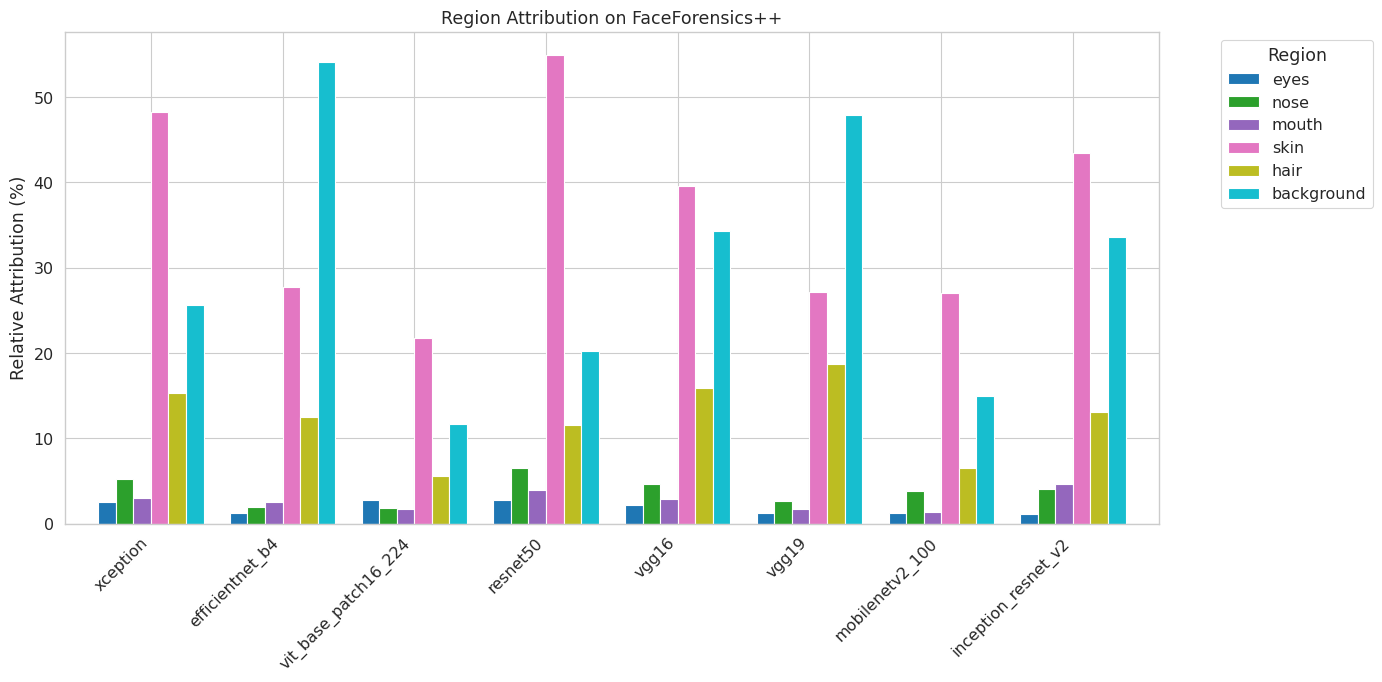

Saved: region_attribution_ff.png


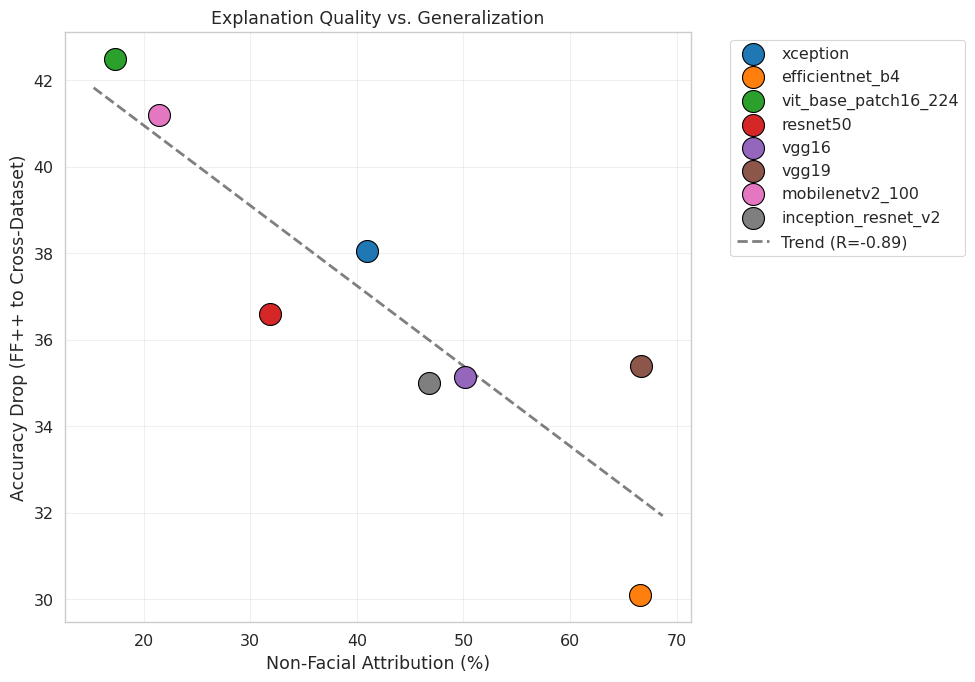

Saved: cross_dataset_drop.png


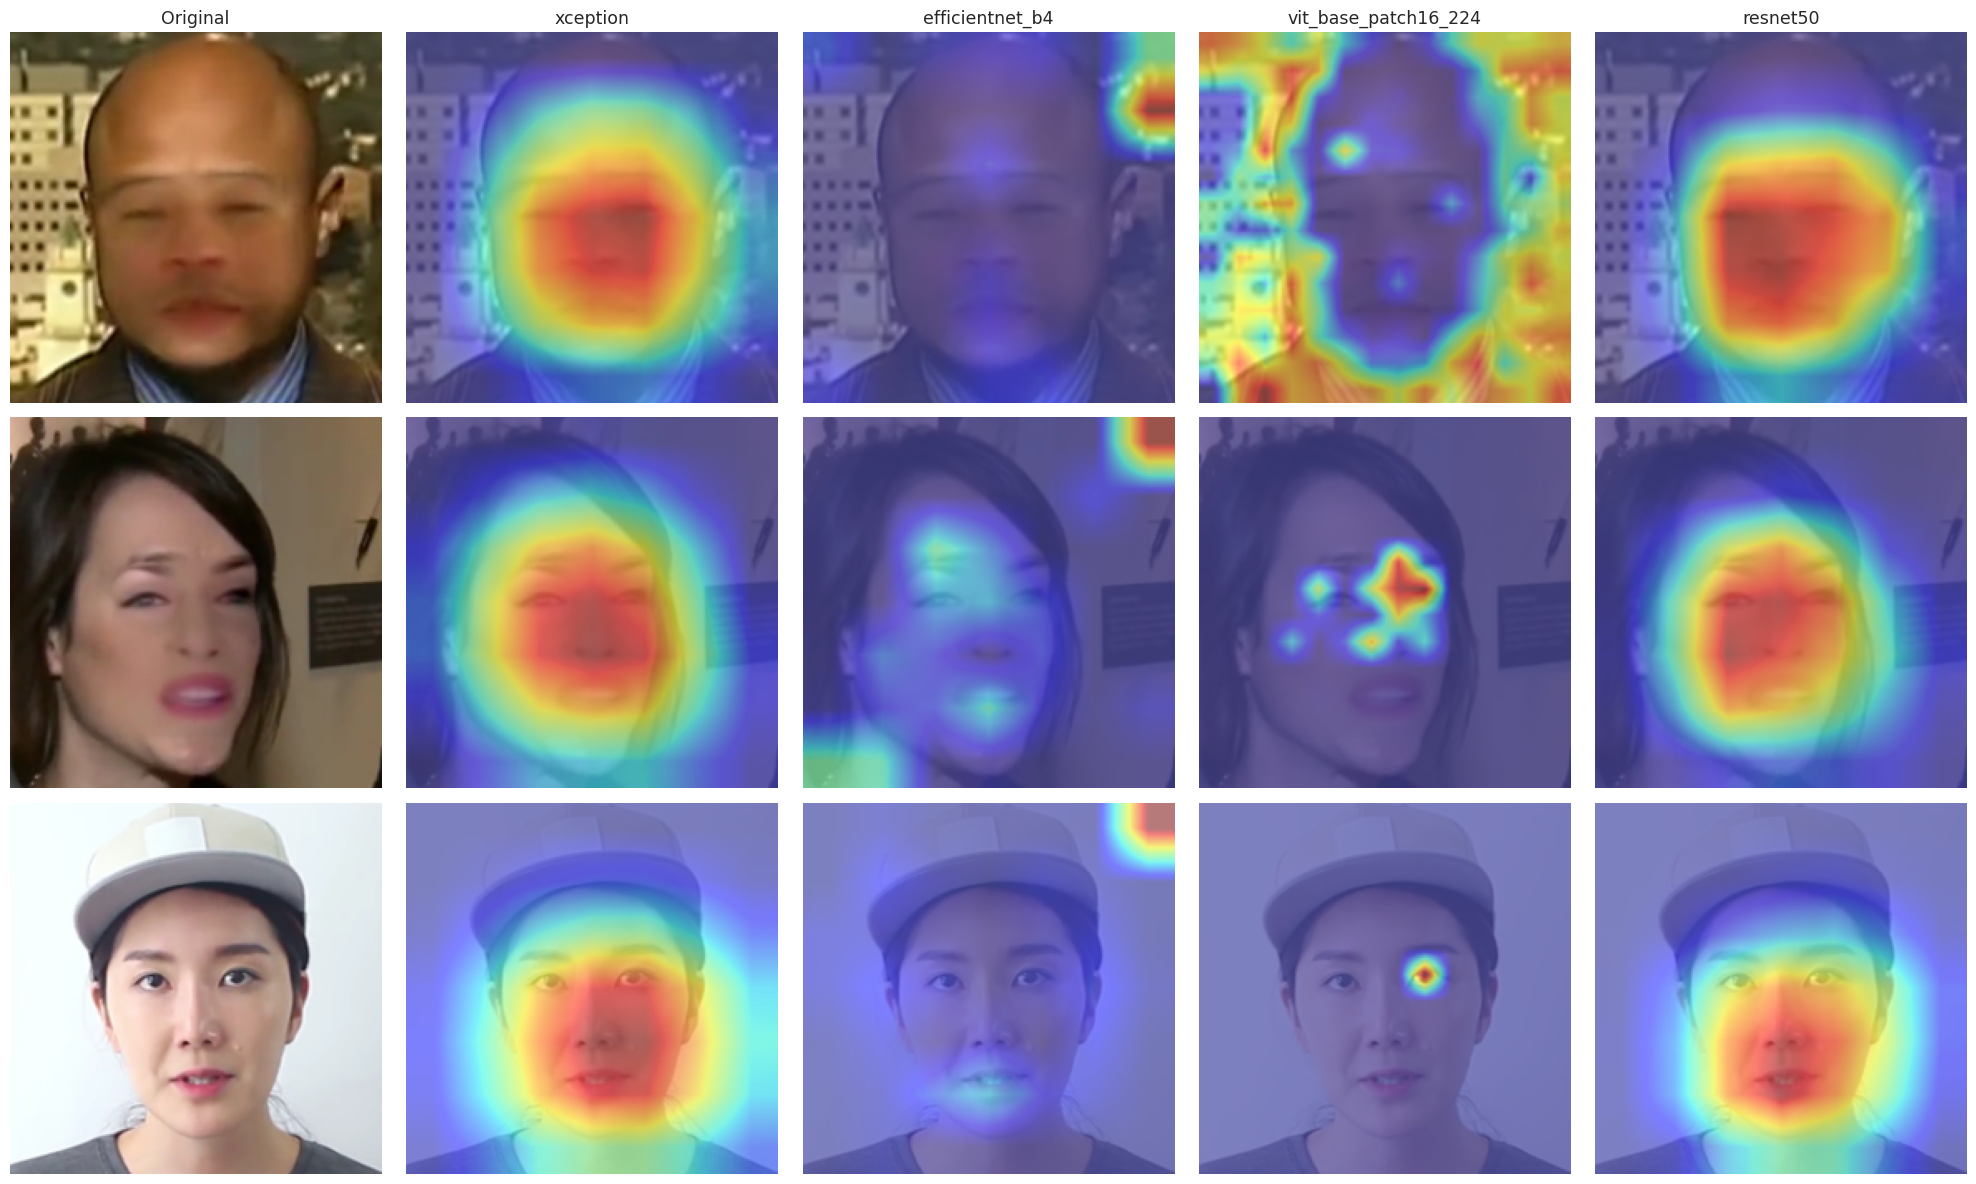

Saved: saliency_examples.png


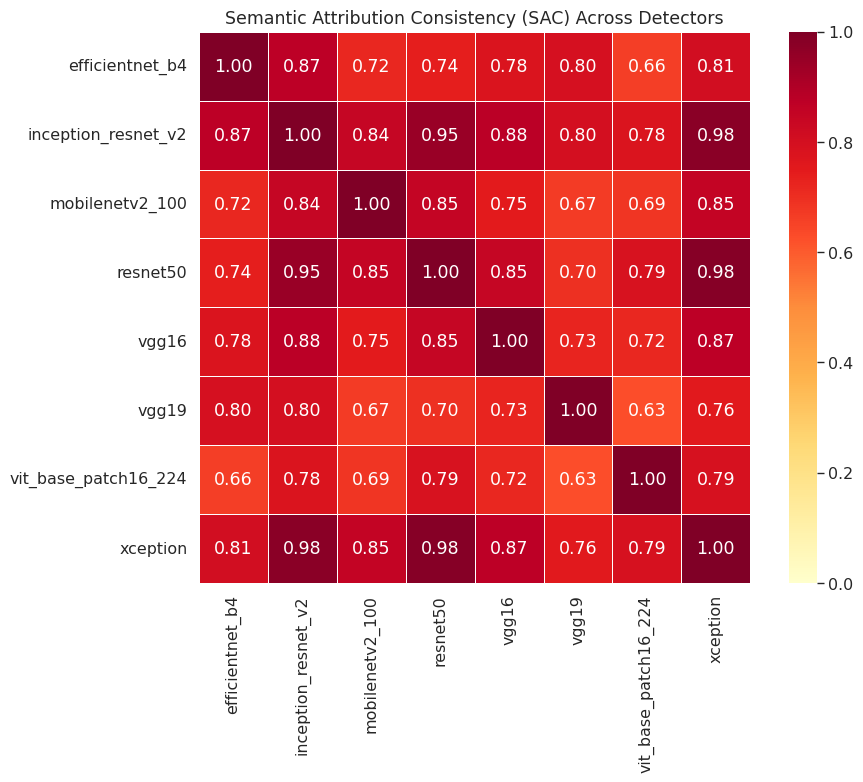

Saved: sac_heatmap.png


In [18]:
sns.set_style("whitegrid")
sns.set_context("paper", font_scale=1.3)

def plot_region_attribution(df, save_name="region_attribution.png", title="Region Attribution"):
    fig, ax = plt.subplots(figsize=(14, 7))
    region_cols = ['eyes', 'nose', 'mouth', 'skin', 'hair', 'background']
    df_plot = df[['model'] + region_cols].set_index('model')
    df_plot.plot(kind='bar', ax=ax, width=0.8, colormap='tab10')
    ax.set_ylabel("Relative Attribution (%)")
    ax.set_xlabel("")
    ax.set_title(title)
    ax.legend(title="Region", bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(f"{WORK_DIR}/figures/{save_name}", dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}")


def plot_cross_dataset_drop(df_ff, df_cross, save_name="cross_dataset_drop.png"):
    if df_ff is None or df_cross is None:
        print("Missing data for cross-dataset plot.")
        return
    df_merged = pd.merge(
        df_ff[['model', 'accuracy', 'non_facial']], 
        df_cross[['model', 'accuracy', 'non_facial']], 
        on='model', suffixes=('_ff', '_cross')
    )
    df_merged['accuracy_drop'] = df_merged['accuracy_ff'] - df_merged['accuracy_cross']

    fig, ax = plt.subplots(figsize=(10, 7))
    palette = sns.color_palette("tab10", len(df_merged))
    for idx, row in df_merged.iterrows():
        ax.scatter(row['non_facial_ff'], row['accuracy_drop'], 
                  s=250, c=[palette[idx]], label=row['model'], edgecolors='black', zorder=3)

    z = np.polyfit(df_merged['non_facial_ff'], df_merged['accuracy_drop'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df_merged['non_facial_ff'].min() - 2, df_merged['non_facial_ff'].max() + 2, 100)
    ax.plot(x_line, p(x_line), 'k--', alpha=0.5, linewidth=2, label=f"Trend (R={np.corrcoef(df_merged['non_facial_ff'], df_merged['accuracy_drop'])[0,1]:.2f})")

    ax.set_xlabel("Non-Facial Attribution (%)")
    ax.set_ylabel("Accuracy Drop (FF++ to Cross-Dataset)")
    ax.set_title("Explanation Quality vs. Generalization")
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{WORK_DIR}/figures/{save_name}", dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}")


def plot_saliency_examples(results_dict, n_examples=3, save_name="saliency_examples.png"):
    models = list(results_dict.keys())[:4]  # Show first 4 models
    fig, axes = plt.subplots(n_examples, len(models) + 1, figsize=(4*(len(models)+1), 4*n_examples))
    if n_examples == 1:
        axes = axes.reshape(1, -1)

    for i in range(n_examples):
        ref_results = results_dict[models[0]]
        if i >= len(ref_results):
            break
        img_path = ref_results[i]['img_path']
        img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Original" if i == 0 else "")
        axes[i, 0].axis('off')

        for j, model_key in enumerate(models):
            result = [r for r in results_dict[model_key] if r['img_path'] == img_path]
            if result:
                saliency = result[0]['saliency_map']
                axes[i, j+1].imshow(img, alpha=0.6)
                axes[i, j+1].imshow(saliency, cmap='jet', alpha=0.5)
                axes[i, j+1].set_title(f"{result[0]['model']}" if i == 0 else "")
                axes[i, j+1].axis('off')

    plt.tight_layout()
    plt.savefig(f"{WORK_DIR}/figures/{save_name}", dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}")


def plot_sac_heatmap(df_sac, save_name="sac_heatmap.png"):
    """Plot SAC as a symmetric heatmap."""
    if df_sac is None or len(df_sac) == 0:
        print("No SAC data for heatmap.")
        return

    # Extract unique models
    models = set()
    for pair in df_sac['model_pair']:
        m1, m2 = pair.split(' vs ')
        models.add(m1)
        models.add(m2)
    models = sorted(list(models))

    # Build symmetric matrix
    sac_matrix = np.ones((len(models), len(models)))
    for _, row in df_sac.iterrows():
        m1, m2 = row['model_pair'].split(' vs ')
        i, j = models.index(m1), models.index(m2)
        sac_matrix[i, j] = row['SAC']
        sac_matrix[j, i] = row['SAC']

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(sac_matrix, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=models, yticklabels=models, vmin=0, vmax=1,
                square=True, linewidths=0.5, ax=ax)
    ax.set_title("Semantic Attribution Consistency (SAC) Across Detectors")
    plt.tight_layout()
    plt.savefig(f"{WORK_DIR}/figures/{save_name}", dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}")


# Generate all figures
if ff_results:
    plot_region_attribution(df_ff, save_name="region_attribution_ff.png", title="Region Attribution on FaceForensics++")

if ff_results and celeb_results:
    plot_cross_dataset_drop(df_ff, df_cross, save_name="cross_dataset_drop.png")

if ff_results:
    plot_saliency_examples(ff_results, n_examples=3, save_name="saliency_examples.png")

if ff_results and 'df_sac_ff' in globals() and df_sac_ff is not None:
    plot_sac_heatmap(df_sac_ff, save_name="sac_heatmap.png")

# # Cell 17: Save Final Summary


In [19]:
summary = {
    "experiment_date": str(pd.Timestamp.now()),
    "configuration": {
        "img_size": IMG_SIZE,
        "train_epochs": TRAIN_EPOCHS,
        "n_train": N_TRAIN,
        "n_test_ff": N_TEST_FF,
        "n_test_cross": N_TEST_CROSS,
        "device": str(DEVICE),
        "n_detectors": len(DETECTORS),
        "detectors": list(DETECTORS.keys())
    },
    "datasets_used": {
        "ff_plus": FFPLUS_AVAILABLE,
        "celeb_df": CELEB_AVAILABLE
    }
}

if ff_results:
    summary["ff_test_accuracy"] = df_ff[['model', 'accuracy']].to_dict('records')
    summary["ff_test_attributions"] = df_ff[['model'] + REGION_NAMES + ['non_facial']].to_dict('records')

if celeb_results:
    summary["cross_dataset_accuracy"] = df_cross[['model', 'accuracy']].to_dict('records')

if ff_results and 'df_sac_ff' in globals() and df_sac_ff is not None:
    summary["sac_scores"] = df_sac_ff.to_dict('records')

with open(f"{WORK_DIR}/experiment_summary.json", 'w') as f:
    json.dump(summary, f, indent=2)

print("\n" + "="*80)
print("EXPERIMENT COMPLETE!")
print("="*80)
print(f"\nResults saved to: {WORK_DIR}")
print(f"  - Figures: {WORK_DIR}/figures/")
print(f"  - Tables: {WORK_DIR}/*.csv")
print(f"  - Checkpoints: {WORK_DIR}/checkpoints/")
print(f"  - Summary: {WORK_DIR}/experiment_summary.json")



EXPERIMENT COMPLETE!

Results saved to: /kaggle/working/trustvis_results
  - Figures: /kaggle/working/trustvis_results/figures/
  - Tables: /kaggle/working/trustvis_results/*.csv
  - Checkpoints: /kaggle/working/trustvis_results/checkpoints/
  - Summary: /kaggle/working/trustvis_results/experiment_summary.json
